# TCGA-KIRC: gene-expression preprocessing

## Purpose

Create a primary-tumour gene-expression dataset that matches to the 522-patient clinical survival-analysis cohort.

## Source
GDC TCGA-KIRC RNA-seq gene-expression quantification files.

In [1]:
# 03-02 Import packages and define project paths

from pathlib import Path
import json

import numpy as np
import pandas as pd

PROJECT_DIR = Path.cwd().parent

RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
RESULTS_DIR = PROJECT_DIR / "results"

for folder in [RAW_DATA_DIR, PROCESSED_DATA_DIR, RESULTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print(f"Project directory: {PROJECT_DIR}")
print(f"Raw-data directory: {RAW_DATA_DIR}")

Project directory: /Users/drsweetyramnani/Documents/Research_Projects/Cancer_genomics-tcga_kirc_survival_analysis
Raw-data directory: /Users/drsweetyramnani/Documents/Research_Projects/Cancer_genomics-tcga_kirc_survival_analysis/data/raw


### 03-03 Retrieve primary-tumour expression-file metadata

**Purpose:** Before dpwnlaoding , check meta-data first.

**Selection criteria:**

- Project: TCGA-KIRC
- Data category: Transcriptome Profiling
- Data type: Gene Expression Quantification
- Workflow: STAR - Counts
- Sample type: Primary Tumor

In [2]:
# 03-03 Retrieving and saving the expression-file

from urllib.parse import urlencode
from urllib.request import urlopen

gdc_files_url = "https://api.gdc.cancer.gov/files"

expression_file_filters = {
    "op": "and",
    "content": [
        {
            "op": "in",
            "content": {
                "field": "cases.project.project_id",
                "value": ["TCGA-KIRC"],
            },
        },
        {
            "op": "in",
            "content": {
                "field": "data_category",
                "value": ["Transcriptome Profiling"],
            },
        },
        {
            "op": "in",
            "content": {
                "field": "data_type",
                "value": ["Gene Expression Quantification"],
            },
        },
        {
            "op": "in",
            "content": {
                "field": "analysis.workflow_type",
                "value": ["STAR - Counts"],
            },
        },
        {
            "op": "in",
            "content": {
                "field": "cases.samples.sample_type",
                "value": ["Primary Tumor"],
            },
        },
    ],
}

expression_file_fields = [
    "file_id",
    "file_name",
    "file_size",
    "md5sum",
    "analysis.workflow_type",
    "cases.submitter_id",
    "cases.samples.sample_type",
]

query = urlencode(
    {
        "filters": json.dumps(expression_file_filters),
        "fields": ",".join(expression_file_fields),
        "format": "JSON",
        "size": 1000,
    }
)

with urlopen(f"{gdc_files_url}?{query}", timeout=60) as response:
    expression_manifest_api = json.load(response)

manifest_json_file = (
    RAW_DATA_DIR / "TCGA-KIRC_STAR_counts_primary_tumor_manifest.json"
)

with open(manifest_json_file, "w") as file:
    json.dump(expression_manifest_api, file, indent=2)

number_of_expression_files = (
    expression_manifest_api["data"]["pagination"]["total"]
)

print(f"Candidate primary-tumour expression files: {number_of_expression_files}")
print(f"Raw manifest saved as: {manifest_json_file.name}")

Candidate primary-tumour expression files: 541
Raw manifest saved as: TCGA-KIRC_STAR_counts_primary_tumor_manifest.json


### 03-04 Inspect expression-file duplication

**Purpose:** Determine how many expression files belong to each patient before
selecting one primary-tumour sample per patient.

In [3]:
# 03-04 Inspecting expression-file duplication

manifest_json_file = (
    RAW_DATA_DIR / "TCGA-KIRC_STAR_counts_primary_tumor_manifest.json"
)

with open(manifest_json_file, "r") as file:
    expression_manifest_api = json.load(file)

manifest_rows = []

for file_record in expression_manifest_api["data"]["hits"]:
    case_records = file_record.get("cases", [])

    patient_ids = sorted(
        {
            case["submitter_id"]
            for case in case_records
            if case.get("submitter_id") is not None
        }
    )

    sample_types = sorted(
        {
            sample["sample_type"]
            for case in case_records
            for sample in case.get("samples", [])
            if sample.get("sample_type") is not None
        }
    )

    manifest_rows.append(
        {
            "file_id": file_record["file_id"],
            "file_name": file_record["file_name"],
            "file_size_MB": round(file_record["file_size"] / 1_000_000, 2),
            "patient_id": "; ".join(patient_ids),
            "sample_type": "; ".join(sample_types),
            "workflow": file_record["analysis"]["workflow_type"],
        }
    )

expression_manifest = pd.DataFrame(manifest_rows)

files_per_patient = expression_manifest["patient_id"].value_counts()

print("Expression files:", len(expression_manifest))
print("Unique patients:", expression_manifest["patient_id"].nunique())
print("Patients with multiple expression files:", (files_per_patient > 1).sum())

print("\nSample types:")
print(expression_manifest["sample_type"].value_counts())

print("\nFiles per patient:")
print(files_per_patient.value_counts().sort_index())

display(expression_manifest.head())

Expression files: 541
Unique patients: 533
Patients with multiple expression files: 4

Sample types:
sample_type
Primary Tumor    541
Name: count, dtype: int64

Files per patient:
count
1    529
3      4
Name: count, dtype: int64


,file_id,file_name,file_size_MB,patient_id,sample_type,workflow
0,fc63bae4-fdfb-4990-9902-3e0fb51ec092,e95ef864-eeee-4883-943c-e2e1eecd259c.rna_seq.a...,4.22,TCGA-BP-4160,Primary Tumor,STAR - Counts
1,4a29721a-1de3-4e14-b905-f39aacb1bd53,1fced4a1-6992-4189-84d9-fddce3e3b937.rna_seq.a...,4.26,TCGA-BP-4965,Primary Tumor,STAR - Counts
2,862e5c87-bed8-4310-b9ed-1018568bdc78,7d160562-b94b-4cd9-9905-d15dadbb394a.rna_seq.a...,4.26,TCGA-BP-4999,Primary Tumor,STAR - Counts
3,813cb150-7ef6-4fa7-9a64-c70f9401513c,6834bc84-328c-49be-b78e-61ffec46ef97.rna_seq.a...,4.25,TCGA-BP-5009,Primary Tumor,STAR - Counts
4,4ea0bf83-1d7e-41da-a34d-221add8155b2,7afb81f7-f9b0-4d0b-a4bd-18c15043c73f.rna_seq.a...,4.25,TCGA-CJ-4894,Primary Tumor,STAR - Counts


All 541 files are primary-tumour samples.
529 patients have one file.
Only 4 patients have three files each.
That means 533 expression patients versus 522 clinical-analysis patients.

### 03-05 Match expression metadata to the clinical cohort

**Purpose:** Confirm which expression patients overlap with the final 522-patient
clinical survival-analysis cohort.

In [4]:
# 03-05 Matching expression metadata to the clinical cohort

clinical_file = (
    PROCESSED_DATA_DIR / "tcga_kirc_clinical_survival_analysis.csv"
)

clinical_data = pd.read_csv(clinical_file)

clinical_patient_ids = set(clinical_data["patient_id"])
expression_patient_ids = set(expression_manifest["patient_id"])

matched_patient_ids = clinical_patient_ids & expression_patient_ids
clinical_only_patient_ids = clinical_patient_ids - expression_patient_ids
expression_only_patient_ids = expression_patient_ids - clinical_patient_ids

print("Clinical survival-analysis patients:", len(clinical_patient_ids))
print("Expression patients:", len(expression_patient_ids))
print("Matched patients:", len(matched_patient_ids))
print("Clinical patients without expression:", len(clinical_only_patient_ids))
print("Expression patients outside clinical cohort:", len(expression_only_patient_ids))

duplicate_expression_files = expression_manifest[
    expression_manifest["patient_id"].isin(
        files_per_patient[files_per_patient > 1].index
    )
].sort_values(["patient_id", "file_id"])

print("\nExpression files for patients with duplicate files:")
display(duplicate_expression_files)

Clinical survival-analysis patients: 522
Expression patients: 533
Matched patients: 518
Clinical patients without expression: 4
Expression patients outside clinical cohort: 15

Expression files for patients with duplicate files:


,file_id,file_name,file_size_MB,patient_id,sample_type,workflow
234,2b393323-81e3-49e2-9acd-18eb8ab0c563,d96fc441-a213-4f24-b2b1-a23d63883532.rna_seq.a...,4.23,TCGA-B2-3923,Primary Tumor,STAR - Counts
41,4134fa64-6365-4a43-b990-48342be44405,2a0d7ffd-21a2-4c9f-b420-9f78e9b8689b.rna_seq.a...,4.21,TCGA-B2-3923,Primary Tumor,STAR - Counts
114,d514c3bc-c1e1-4028-9822-90ad703a3a8d,d5340889-fb1c-411d-922c-a9f69e1ac405.rna_seq.a...,4.21,TCGA-B2-3923,Primary Tumor,STAR - Counts
197,056c67e7-03b3-40cc-8c19-d6938ad634aa,343ac8e1-8afa-4e36-a373-ca28c3e7a713.rna_seq.a...,4.24,TCGA-B2-3924,Primary Tumor,STAR - Counts
522,3324e6df-28f9-42d8-8465-0fcc2d618004,f08c47f7-7b61-46a2-a961-d5fced8ebde5.rna_seq.a...,4.24,TCGA-B2-3924,Primary Tumor,STAR - Counts
132,df630d23-f007-4cc4-9910-edb44046d556,a40c1d70-1750-45d0-a85b-688331b029ea.rna_seq.a...,4.20,TCGA-B2-3924,Primary Tumor,STAR - Counts
100,307fc027-0530-452b-8fa9-d46f7fc73d0e,9cc9f5b7-bbbb-4d3b-8d98-9bf4425a214b.rna_seq.a...,4.24,TCGA-B2-5633,Primary Tumor,STAR - Counts
227,61894bd0-9fdb-4bb1-b32c-f52dbc10c850,1e28caa3-197f-4deb-95c1-f6d8a41756ca.rna_seq.a...,4.24,TCGA-B2-5633,Primary Tumor,STAR - Counts
99,bdb74506-8766-42e1-922e-e03da4637a70,dc6421de-439b-4764-87bf-c1922cfeba3c.rna_seq.a...,4.22,TCGA-B2-5633,Primary Tumor,STAR - Counts
379,2afa2c24-7bbf-4855-acb8-feaa22dc4c33,27ea00ff-5f53-4110-9e56-8674a8e0ae40.rna_seq.a...,4.23,TCGA-B2-5635,Primary Tumor,STAR - Counts


518 patients have both usable clinical and expression data.
4 clinical-analysis patients have no matching expression file.
Gene models would be able to use the matched 518-patient cohort.

### 03-06 Gene expression

**Purpose:** Inspect clinical patients without expression data and identify matched
patients with multiple expression files.

In [5]:
# 03-06 Gene expression

file_count_by_patient = (
    expression_manifest["patient_id"]
    .value_counts()
    .rename("expression_file_count")
)

clinical_expression_coverage = clinical_data.merge(
    file_count_by_patient,
    left_on="patient_id",
    right_index=True,
    how="left",
)

clinical_without_expression = clinical_expression_coverage[
    clinical_expression_coverage["expression_file_count"].isna()
].copy()

clinical_patients_with_multiple_files = clinical_expression_coverage[
    clinical_expression_coverage["expression_file_count"] > 1
].copy()

print("Clinical patients without expression files:")
display(
    clinical_without_expression[
        [
            "patient_id",
            "sex_at_birth",
            "age_at_index",
            "tumor_stage",
            "tumor_grade",
            "event_observed",
            "overall_survival_days",
        ]
    ].sort_values("patient_id")
)

print("\nMatched clinical patients with multiple expression files:")
display(
    clinical_patients_with_multiple_files[
        [
            "patient_id",
            "expression_file_count",
            "tumor_stage",
            "tumor_grade",
            "event_observed",
        ]
    ].sort_values("patient_id")
)

Clinical patients without expression files:


,patient_id,sex_at_birth,age_at_index,tumor_stage,tumor_grade,event_observed,overall_survival_days
238,TCGA-A3-3336,female,75,Stage I,G4,0,1043.0
241,TCGA-AK-3430,male,61,Stage III,G3,1,480.0
209,TCGA-CJ-4913,female,45,Stage III,G4,1,1173.0
278,TCGA-CW-6096,female,44,Stage I,G2,0,2701.0



Matched clinical patients with multiple expression files:


,patient_id,expression_file_count,tumor_stage,tumor_grade,event_observed
474,TCGA-B2-3923,3.0,Stage II,G2,0
255,TCGA-B2-3924,3.0,Stage I,G2,0
360,TCGA-B2-5633,3.0,Stage I,G2,0
302,TCGA-B2-5635,3.0,Stage I,G2,0


four unmatched patients lack a matching Counts file, so they will be excluded only from expression-based analyses

### 03-07 Inspect duplicate expression metadata

**Purpose:** Identify the sample and aliquot identifiers for the 12 duplicate-file
records so that I can apply a one-file-per-patient rule.


In [6]:
# 03-07 Inspect duplicate expression  metadata

from urllib.parse import urlencode
from urllib.request import urlopen

duplicate_patient_ids = files_per_patient[
    files_per_patient > 1
].index.tolist()

duplicate_file_ids = expression_manifest.loc[
    expression_manifest["patient_id"].isin(duplicate_patient_ids),
    "file_id",
].tolist()

duplicate_file_filter = {
    "op": "in",
    "content": {
        "field": "file_id",
        "value": duplicate_file_ids,
    },
}

duplicate_file_fields = [
    "file_id",
    "file_name",
    "file_size",
    "md5sum",
    "created_datetime",
    "updated_datetime",
    "cases.submitter_id",
    "cases.samples.submitter_id",
    "cases.samples.sample_type",
    "cases.samples.portions.analytes.aliquots.submitter_id",
]

query = urlencode(
    {
        "filters": json.dumps(duplicate_file_filter),
        "fields": ",".join(duplicate_file_fields),
        "format": "JSON",
        "size": 100,
    }
)

with urlopen(f"{gdc_files_url}?{query}", timeout=60) as response:
    duplicate_metadata_api = json.load(response)

duplicate_metadata_file = (
    RAW_DATA_DIR / "TCGA-KIRC_duplicate_expression_file_metadata.json"
)

with open(duplicate_metadata_file, "w") as file:
    json.dump(duplicate_metadata_api, file, indent=2)

duplicate_rows = []

for file_record in duplicate_metadata_api["data"]["hits"]:
    for case in file_record.get("cases", []):
        for sample in case.get("samples", []):
            duplicate_rows.append(
                {
                    "patient_id": case.get("submitter_id"),
                    "sample_id": sample.get("submitter_id"),
                    "sample_type": sample.get("sample_type"),
                    "file_id": file_record["file_id"],
                    "file_size_MB": round(
                        file_record["file_size"] / 1_000_000,
                        2,
                    ),
                    "created_datetime": file_record.get("created_datetime"),
                }
            )

duplicate_metadata_table = pd.DataFrame(duplicate_rows)

print("Duplicate-file metadata saved as:", duplicate_metadata_file.name)
display(
    duplicate_metadata_table.sort_values(
        ["patient_id", "sample_id", "created_datetime"]
    )
)

Duplicate-file metadata saved as: TCGA-KIRC_duplicate_expression_file_metadata.json


,patient_id,sample_id,sample_type,file_id,file_size_MB,created_datetime
8,TCGA-B2-3923,TCGA-B2-3923-01A,Primary Tumor,2b393323-81e3-49e2-9acd-18eb8ab0c563,4.23,2021-12-13T19:40:11.094009-06:00
0,TCGA-B2-3923,TCGA-B2-3923-01A,Primary Tumor,4134fa64-6365-4a43-b990-48342be44405,4.21,2021-12-13T19:41:23.595377-06:00
3,TCGA-B2-3923,TCGA-B2-3923-01B,Primary Tumor,d514c3bc-c1e1-4028-9822-90ad703a3a8d,4.21,2021-12-13T19:40:22.232781-06:00
5,TCGA-B2-3924,TCGA-B2-3924-01A,Primary Tumor,056c67e7-03b3-40cc-8c19-d6938ad634aa,4.24,2021-12-13T19:39:38.741766-06:00
4,TCGA-B2-3924,TCGA-B2-3924-01A,Primary Tumor,df630d23-f007-4cc4-9910-edb44046d556,4.20,2021-12-13T19:40:43.661964-06:00
11,TCGA-B2-3924,TCGA-B2-3924-01B,Primary Tumor,3324e6df-28f9-42d8-8465-0fcc2d618004,4.24,2021-12-13T19:36:58.453496-06:00
1,TCGA-B2-5633,TCGA-B2-5633-01A,Primary Tumor,bdb74506-8766-42e1-922e-e03da4637a70,4.22,2021-12-13T19:05:40.926507-06:00
7,TCGA-B2-5633,TCGA-B2-5633-01A,Primary Tumor,61894bd0-9fdb-4bb1-b32c-f52dbc10c850,4.24,2021-12-13T19:23:48.703490-06:00
2,TCGA-B2-5633,TCGA-B2-5633-01B,Primary Tumor,307fc027-0530-452b-8fa9-d46f7fc73d0e,4.24,2021-12-13T19:04:47.831519-06:00
10,TCGA-B2-5635,TCGA-B2-5635-01A,Primary Tumor,ebd01ba8-06cd-417a-b41d-05379e430fd2,4.22,2021-12-13T19:12:19.805275-06:00


As seen here : each patient has primary-tumour samples 01A and 01B, and some 01A samples have two aliquot-level expression files

### 03-08 Inspect duplicate aliquot identifiers

**Purpose:** Identify aliquot IDs for duplicate `01A` expression files.

In [7]:
# 03-08 Inspect duplicate aliquot identifiers

aliquot_rows = []

for file_record in duplicate_metadata_api["data"]["hits"]:
    for case in file_record.get("cases", []):
        for sample in case.get("samples", []):
            for portion in sample.get("portions", []):
                for analyte in portion.get("analytes", []):
                    for aliquot in analyte.get("aliquots", []):
                        aliquot_rows.append(
                            {
                                "patient_id": case.get("submitter_id"),
                                "sample_id": sample.get("submitter_id"),
                                "aliquot_id": aliquot.get("submitter_id"),
                                "file_id": file_record["file_id"],
                            }
                        )

duplicate_aliquot_table = pd.DataFrame(aliquot_rows)

print("Aliquot records found:", len(duplicate_aliquot_table))

display(
    duplicate_aliquot_table.sort_values(
        ["patient_id", "sample_id", "aliquot_id"]
    )
)

Aliquot records found: 12


,patient_id,sample_id,aliquot_id,file_id
8,TCGA-B2-3923,TCGA-B2-3923-01A,TCGA-B2-3923-01A-02R-1325-07,2b393323-81e3-49e2-9acd-18eb8ab0c563
0,TCGA-B2-3923,TCGA-B2-3923-01A,TCGA-B2-3923-01A-02R-A277-07,4134fa64-6365-4a43-b990-48342be44405
3,TCGA-B2-3923,TCGA-B2-3923-01B,TCGA-B2-3923-01B-10R-A277-07,d514c3bc-c1e1-4028-9822-90ad703a3a8d
5,TCGA-B2-3924,TCGA-B2-3924-01A,TCGA-B2-3924-01A-02R-1325-07,056c67e7-03b3-40cc-8c19-d6938ad634aa
4,TCGA-B2-3924,TCGA-B2-3924-01A,TCGA-B2-3924-01A-02R-A277-07,df630d23-f007-4cc4-9910-edb44046d556
11,TCGA-B2-3924,TCGA-B2-3924-01B,TCGA-B2-3924-01B-03R-A277-07,3324e6df-28f9-42d8-8465-0fcc2d618004
7,TCGA-B2-5633,TCGA-B2-5633-01A,TCGA-B2-5633-01A-01R-1541-07,61894bd0-9fdb-4bb1-b32c-f52dbc10c850
1,TCGA-B2-5633,TCGA-B2-5633-01A,TCGA-B2-5633-01A-01R-A277-07,bdb74506-8766-42e1-922e-e03da4637a70
2,TCGA-B2-5633,TCGA-B2-5633-01B,TCGA-B2-5633-01B-04R-A277-07,307fc027-0530-452b-8fa9-d46f7fc73d0e
6,TCGA-B2-5635,TCGA-B2-5635-01A,TCGA-B2-5635-01A-01R-1541-07,b98e59fc-120a-45c4-aade-3b59ca4a1a86


Keeping only the 518 patients matched to the clinical cohort.
For duplicate patients, I would use sample 01A preferably.
If two 01A aliquots exist, I plan to use: lexicographically first aliquot ID. Later,I will run a sensitivity check excluding these four multi-sampled patients.

### 03-09 Select one expression file per matched patient

**Purpose:** raw data 518-file download.

**Selection rule:** Prefer primary-tumour sample `01A`; break remaining ties using the lexicographically first aliquot identifier.

In [8]:
# 03-09 Selecting one expression file per matched patient

duplicate_lookup = duplicate_aliquot_table.drop_duplicates(
    subset="file_id"
)

matched_expression_files = expression_manifest[
    expression_manifest["patient_id"].isin(matched_patient_ids)
].copy()

matched_expression_files = matched_expression_files.merge(
    duplicate_lookup[
        ["file_id", "sample_id", "aliquot_id"]
    ],
    on="file_id",
    how="left",
)

matched_expression_files["sample_priority"] = np.where(
    matched_expression_files["sample_id"].fillna("").str.endswith("01A"),
    0,
    1,
)

matched_expression_files["aliquot_sort_key"] = (
    matched_expression_files["aliquot_id"]
    .fillna("single_file")
)

selected_expression_files = (
    matched_expression_files
    .sort_values(
        ["patient_id", "sample_priority", "aliquot_sort_key", "file_id"]
    )
    .drop_duplicates(subset="patient_id", keep="first")
    .copy()
)

selected_expression_files["selection_reason"] = np.where(
    selected_expression_files["patient_id"].map(files_per_patient).eq(1),
    "single_primary_tumor_file",
    "preferred_01A_then_aliquot",
)

selected_expression_files = selected_expression_files[
    [
        "patient_id",
        "file_id",
        "file_name",
        "file_size_MB",
        "sample_id",
        "aliquot_id",
        "selection_reason",
    ]
].sort_values("patient_id")

assert selected_expression_files["patient_id"].is_unique
assert len(selected_expression_files) == len(matched_patient_ids)

selection_manifest_file = (
    PROJECT_DIR / "docs" / "tcga_kirc_expression_file_selection.csv"
)

selected_expression_files.to_csv(
    selection_manifest_file,
    index=False,
)

print("Selected expression files:", len(selected_expression_files))
print("\nSelection reasons:")
print(selected_expression_files["selection_reason"].value_counts())

print(f"\nSelection manifest saved as: {selection_manifest_file.name}")

print("\nSelected files for duplicate-file patients:")
display(
    selected_expression_files[
        selected_expression_files["selection_reason"]
        == "preferred_01A_then_aliquot"
    ]
)

Selected expression files: 518

Selection reasons:
selection_reason
single_primary_tumor_file     514
preferred_01A_then_aliquot      4
Name: count, dtype: int64

Selection manifest saved as: tcga_kirc_expression_file_selection.csv

Selected files for duplicate-file patients:


,patient_id,file_id,file_name,file_size_MB,sample_id,aliquot_id,selection_reason
230,TCGA-B2-3923,2b393323-81e3-49e2-9acd-18eb8ab0c563,d96fc441-a213-4f24-b2b1-a23d63883532.rna_seq.a...,4.23,TCGA-B2-3923-01A,TCGA-B2-3923-01A-02R-1325-07,preferred_01A_then_aliquot
194,TCGA-B2-3924,056c67e7-03b3-40cc-8c19-d6938ad634aa,343ac8e1-8afa-4e36-a373-ca28c3e7a713.rna_seq.a...,4.24,TCGA-B2-3924-01A,TCGA-B2-3924-01A-02R-1325-07,preferred_01A_then_aliquot
223,TCGA-B2-5633,61894bd0-9fdb-4bb1-b32c-f52dbc10c850,1e28caa3-197f-4deb-95c1-f6d8a41756ca.rna_seq.a...,4.24,TCGA-B2-5633-01A,TCGA-B2-5633-01A-01R-1541-07,preferred_01A_then_aliquot
214,TCGA-B2-5635,b98e59fc-120a-45c4-aade-3b59ca4a1a86,c276c214-acd9-44b3-b932-971c77c4fa91.rna_seq.a...,4.24,TCGA-B2-5635-01A,TCGA-B2-5635-01A-01R-1541-07,preferred_01A_then_aliquot


### 03-10  GDC file download

In [9]:
# 03-10 GDC downlaod 

import shutil

manifest_json_file = (
    RAW_DATA_DIR / "TCGA-KIRC_STAR_counts_primary_tumor_manifest.json"
)

with open(manifest_json_file, "r") as file:
    original_manifest_api = json.load(file)

gdc_file_metadata = pd.DataFrame(
    [
        {
            "id": file_record["file_id"],
            "filename": file_record["file_name"],
            "md5": file_record["md5sum"],
            "size": file_record["file_size"],
            "state": "released",
        }
        for file_record in original_manifest_api["data"]["hits"]
    ]
)

gdc_download_manifest = selected_expression_files.merge(
    gdc_file_metadata,
    left_on="file_id",
    right_on="id",
    how="left",
    validate="one_to_one",
)

assert gdc_download_manifest["md5"].notna().all()

gdc_download_manifest = gdc_download_manifest[
    ["id", "filename", "md5", "size", "state"]
]

gdc_manifest_file = (
    RAW_DATA_DIR / "TCGA-KIRC_STAR_counts_download_manifest.tsv"
)

gdc_download_manifest.to_csv(
    gdc_manifest_file,
    sep="\t",
    index=False,
)

total_download_GB = gdc_download_manifest["size"].sum() / 1_000_000_000
free_disk_GB = shutil.disk_usage(PROJECT_DIR).free / 1_000_000_000

print(f"Files in download manifest: {len(gdc_download_manifest)}")
print(f"Expected download size: {total_download_GB:.2f} GB")
print(f"Free disk space: {free_disk_GB:.2f} GB")
print(f"Manifest saved as: {gdc_manifest_file.name}")

display(gdc_download_manifest.head())

Files in download manifest: 518
Expected download size: 2.20 GB
Free disk space: 417.51 GB
Manifest saved as: TCGA-KIRC_STAR_counts_download_manifest.tsv


,id,filename,md5,size,state
0,21702617-18af-41b6-98fa-54395bfd0d9a,c3b9c2b0-bd3d-43ff-a17f-797122d5ac3c.rna_seq.a...,2ba3d2c621a7156e735f0665c3f12e67,4228535,released
1,44dade70-3ecc-4be0-88a8-772cb763d5bb,e4497835-a45f-488e-905c-b06d578efef8.rna_seq.a...,d199c5212d05d4700b3e453962b787da,4231641,released
2,c1215d68-5b15-44c3-9d25-73a77b0b5f31,55599384-574d-44e9-aa61-96d27b54aff1.rna_seq.a...,fdc22fe3a0a24efb0b34113a68c81f55,4229992,released
3,b605224a-cf9c-4092-beb4-5ed43c1179de,78855102-69a0-454f-b67a-c0919dc154fb.rna_seq.a...,8204dfa7f15942e2939f46baa0933d26,4238896,released
4,7b34b9d4-8526-4738-87b4-f9435a1c7ae1,598575d0-6dc4-4d59-be17-5dff01e6ca52.rna_seq.a...,88f90a817d5098bc844a189a5e79f2ff,4244120,released


### 03-11 Verify GDC expression downloads

**Purpose:** Confirm that all 518 selected expression files were downloaded.

In [10]:
# 03-11 Verifying GDC expression downloads

GDC_DOWNLOAD_DIR = RAW_DATA_DIR / "gdc_star_counts"

selected_expression_files["local_file"] = selected_expression_files.apply(
    lambda row: GDC_DOWNLOAD_DIR / row["file_id"] / row["file_name"],
    axis=1,
)

selected_expression_files["downloaded"] = (
    selected_expression_files["local_file"]
    .apply(lambda path: path.exists())
)

selected_expression_files["local_size_MB"] = (
    selected_expression_files["local_file"]
    .apply(
        lambda path: round(path.stat().st_size / 1_000_000, 2)
        if path.exists()
        else np.nan
    )
)

print("Selected files:", len(selected_expression_files))
print("Downloaded files:", selected_expression_files["downloaded"].sum())
print("Missing files:", (~selected_expression_files["downloaded"]).sum())

assert selected_expression_files["downloaded"].all()

print(
    "Total downloaded size:",
    f"{selected_expression_files['local_size_MB'].sum():.2f} MB",
)

display(
    selected_expression_files[
        [
            "patient_id",
            "file_id",
            "file_name",
            "local_size_MB",
        ]
    ].head()
)


Selected files: 518
Downloaded files: 518
Missing files: 0
Total downloaded size: 2197.49 MB


,patient_id,file_id,file_name,local_size_MB
28,TCGA-3Z-A93Z,21702617-18af-41b6-98fa-54395bfd0d9a,c3b9c2b0-bd3d-43ff-a17f-797122d5ac3c.rna_seq.a...,4.23
311,TCGA-6D-AA2E,44dade70-3ecc-4be0-88a8-772cb763d5bb,e4497835-a45f-488e-905c-b06d578efef8.rna_seq.a...,4.23
488,TCGA-A3-3306,c1215d68-5b15-44c3-9d25-73a77b0b5f31,55599384-574d-44e9-aa61-96d27b54aff1.rna_seq.a...,4.23
366,TCGA-A3-3307,b605224a-cf9c-4092-beb4-5ed43c1179de,78855102-69a0-454f-b67a-c0919dc154fb.rna_seq.a...,4.24
385,TCGA-A3-3308,7b34b9d4-8526-4738-87b4-f9435a1c7ae1,598575d0-6dc4-4d59-be17-5dff01e6ca52.rna_seq.a...,4.24


### 03-12 Inspect raw GDC STAR - Counts format

**Purpose:** Examine column names and special rows in one downloaded file before
extracting TPM expression values from all files.

In [11]:
# 03-12 Inspect raw GDC STAR - Counts format

example_file = selected_expression_files["local_file"].iloc[0]

print("Example file:")
print(example_file.name)

print("\nFirst eight raw lines:")
with open(example_file, "r") as file:
    for line_number in range(8):
        print(file.readline().rstrip())

example_expression = pd.read_csv(
    example_file,
    sep="\t",
    nrows=10,
)

print("\nColumn names:")
print(list(example_expression.columns))

print("\nFirst ten rows:")
display(example_expression)

Example file:
c3b9c2b0-bd3d-43ff-a17f-797122d5ac3c.rna_seq.augmented_star_gene_counts.tsv

First eight raw lines:
# gene-model: GENCODE v36
gene_id	gene_name	gene_type	unstranded	stranded_first	stranded_second	tpm_unstranded	fpkm_unstranded	fpkm_uq_unstranded
N_unmapped			7003743	7003743	7003743
N_multimapping			3187072	3187072	3187072
N_noFeature			1420057	18511485	18573172
N_ambiguous			4126626	967349	962742
ENSG00000000003.15	TSPAN6	protein_coding	1497	729	768	33.4519	10.4572	10.4794
ENSG00000000005.6	TNMD	protein_coding	20	11	9	1.3735	0.4294	0.4303

Column names:
['# gene-model: GENCODE v36']

First ten rows:


,,,,,,,,# gene-model: GENCODE v36
gene_id,gene_name,gene_type,unstranded,stranded_first,stranded_second,tpm_unstranded,fpkm_unstranded,fpkm_uq_unstranded
N_unmapped,NaN,NaN,7003743,7003743,7003743,NaN,NaN,NaN
N_multimapping,NaN,NaN,3187072,3187072,3187072,NaN,NaN,NaN
N_noFeature,NaN,NaN,1420057,18511485,18573172,NaN,NaN,NaN
N_ambiguous,NaN,NaN,4126626,967349,962742,NaN,NaN,NaN
ENSG00000000003.15,TSPAN6,protein_coding,1497,729,768,33.4519,10.4572,10.4794
ENSG00000000005.6,TNMD,protein_coding,20,11,9,1.3735,0.4294,0.4303
ENSG00000000419.13,DPM1,protein_coding,1318,654,664,110.6828,34.6000,34.6732
ENSG00000000457.14,SCYL3,protein_coding,247,251,220,3.6374,1.1371,1.1395
ENSG00000000460.17,C1orf112,protein_coding,91,161,174,1.5450,0.4830,0.4840


### 03-13 Read one expression file correctly

**Purpose:** Remove metadata and alignment-summary rows, then inspect valid gene rows.

In [12]:
# 03-13 Read one expression file correctly

example_expression = pd.read_csv(
    example_file,
    sep="\t",
    skiprows=1,
)

gene_rows = example_expression[
    example_expression["gene_type"].notna()
].copy()

gene_rows["gene_id_without_version"] = (
    gene_rows["gene_id"].str.split(".").str[0]
)

print("Rows in raw file:", len(example_expression))
print("Valid gene rows:", len(gene_rows))
print("Alignment-summary rows removed:", len(example_expression) - len(gene_rows))

print("\nDuplicate Ensembl gene IDs:")
print(gene_rows["gene_id_without_version"].duplicated().sum())

print("\nDuplicate gene symbols:")
print(gene_rows["gene_name"].duplicated().sum())

display(
    gene_rows[
        [
            "gene_id_without_version",
            "gene_name",
            "gene_type",
            "tpm_unstranded",
        ]
    ].head()
)

Rows in raw file: 60664
Valid gene rows: 60660
Alignment-summary rows removed: 4

Duplicate Ensembl gene IDs:
44

Duplicate gene symbols:
1233


,gene_id_without_version,gene_name,gene_type,tpm_unstranded
4,ENSG00000000003,TSPAN6,protein_coding,33.4519
5,ENSG00000000005,TNMD,protein_coding,1.3735
6,ENSG00000000419,DPM1,protein_coding,110.6828
7,ENSG00000000457,SCYL3,protein_coding,3.6374
8,ENSG00000000460,C1orf112,protein_coding,1.5450


The file contains 60,660 gene rows after removing the four summary rows. Note : gene symbols are not unique, so I must not use gene symbols as the matrix row identifier. I will use the full versioned Ensembl gene_id as the stable identifier and keep gene_name as annotation

### 03-14 Inspect duplicate gene identifiers

**Purpose:** Confirm whether full Ensembl IDs are unique and inspect examples of
duplicate gene symbols.

In [13]:
# 03-14 Inspect duplicate gene identifiers

print("Duplicate full Ensembl IDs:")
print(gene_rows["gene_id"].duplicated().sum())

print("\nDuplicate Ensembl IDs after removing version:")
print(gene_rows["gene_id_without_version"].duplicated().sum())

print("\nDuplicate gene symbols:")
print(gene_rows["gene_name"].duplicated().sum())

print("\nExamples of duplicate full Ensembl IDs:")
display(
    gene_rows[
        gene_rows["gene_id"].duplicated(keep=False)
    ][
        [
            "gene_id",
            "gene_name",
            "gene_type",
            "tpm_unstranded",
        ]
    ].head(12)
)

print("\nExamples of duplicate gene symbols:")
display(
    gene_rows[
        gene_rows["gene_name"].duplicated(keep=False)
    ][
        [
            "gene_id",
            "gene_name",
            "gene_type",
            "tpm_unstranded",
        ]
    ].sort_values("gene_name").head(12)
)

Duplicate full Ensembl IDs:
0

Duplicate Ensembl IDs after removing version:
44

Duplicate gene symbols:
1233

Examples of duplicate full Ensembl IDs:


,gene_id,gene_name,gene_type,tpm_unstranded



Examples of duplicate gene symbols:


,gene_id,gene_name,gene_type,tpm_unstranded
54329,ENSG00000277488.1,5S_rRNA,rRNA,0.0000
54286,ENSG00000277411.1,5S_rRNA,rRNA,1.9125
58358,ENSG00000285912.1,5S_rRNA,rRNA_pseudogene,0.0000
58229,ENSG00000285776.1,5S_rRNA,rRNA_pseudogene,0.0000
58132,ENSG00000285674.1,5S_rRNA,rRNA_pseudogene,0.0000
58084,ENSG00000285626.1,5S_rRNA,rRNA_pseudogene,0.0000
58068,ENSG00000285609.1,5S_rRNA,rRNA_pseudogene,0.0000
60607,ENSG00000288601.1,5S_rRNA,rRNA_pseudogene,0.0000
54028,ENSG00000276861.1,5S_rRNA,rRNA,0.0000
54034,ENSG00000276871.1,5_8S_rRNA,rRNA,0.0000


resutls onfirmed the row key: Ensembl gene_id is unique.; Gene symbols are not unique, mostly because of rRNA and pseudogene entries. I will retain only protein_coding genes, but keep full Ensembl IDs as matrix rows.

### 03-15 Define protein-coding gene rows

**Purpose:** Restrict expression preprocessing to protein-coding genes while keeping
full Ensembl IDs as unique row identifiers.

In [14]:
# 03-15 Define protein-coding gene rows

protein_coding_genes = gene_rows[
    gene_rows["gene_type"] == "protein_coding"
].copy()

print("All valid gene rows:", len(gene_rows))
print("Protein-coding gene rows:", len(protein_coding_genes))
print(
    "Duplicate full Ensembl IDs among protein-coding genes:",
    protein_coding_genes["gene_id"].duplicated().sum(),
)
print(
    "Duplicate symbols among protein-coding genes:",
    protein_coding_genes["gene_name"].duplicated().sum(),
)

display(
    protein_coding_genes[
        ["gene_id", "gene_name", "tpm_unstranded"]
    ].head()
)

All valid gene rows: 60660
Protein-coding gene rows: 19962
Duplicate full Ensembl IDs among protein-coding genes: 0
Duplicate symbols among protein-coding genes: 24


,gene_id,gene_name,tpm_unstranded
4,ENSG00000000003.15,TSPAN6,33.4519
5,ENSG00000000005.6,TNMD,1.3735
6,ENSG00000000419.13,DPM1,110.6828
7,ENSG00000000457.14,SCYL3,3.6374
8,ENSG00000000460.17,C1orf112,1.5450


### 03-16 Build the protein-coding TPM matrix

**Purpose:** Extract `tpm_unstranded` values from all selected files.

**Output:** A 19,962-gene × 518-patient matrix saved.

In [15]:
# 03-16 Building the protein-coding TPM matrix

reference_annotation = protein_coding_genes[
    ["gene_id", "gene_name", "gene_type"]
].set_index("gene_id")

reference_gene_ids = reference_annotation.index
expression_columns = []

for file_number, file_row in enumerate(
    selected_expression_files.itertuples(index=False),
    start=1,
):
    sample_expression = pd.read_csv(
        file_row.local_file,
        sep="\t",
        skiprows=1,
        usecols=["gene_id", "gene_type", "tpm_unstranded"],
    )

    sample_protein_coding = sample_expression[
        sample_expression["gene_type"] == "protein_coding"
    ].set_index("gene_id")

    if not sample_protein_coding.index.equals(reference_gene_ids):
        raise ValueError(
            f"Gene order or gene IDs differ for patient {file_row.patient_id}"
        )

    patient_expression = pd.Series(
        sample_protein_coding["tpm_unstranded"]
        .astype("float32")
        .to_numpy(),
        index=reference_gene_ids,
        name=file_row.patient_id,
    )

    expression_columns.append(patient_expression)

    if file_number % 50 == 0 or file_number == len(selected_expression_files):
        print(
            f"Processed {file_number} of "
            f"{len(selected_expression_files)} files"
        )

expression_tpm = pd.concat(expression_columns, axis=1)

assert expression_tpm.shape == (
    len(reference_gene_ids),
    len(selected_expression_files),
)
assert expression_tpm.columns.is_unique
assert expression_tpm.isna().sum().sum() == 0

gene_annotation_file = (
    PROCESSED_DATA_DIR / "tcga_kirc_protein_coding_gene_annotation.csv"
)

expression_tpm_file = (
    PROCESSED_DATA_DIR / "tcga_kirc_tpm_protein_coding_by_patient.pkl.gz"
)

reference_annotation.to_csv(
    gene_annotation_file,
    index_label="gene_id",
)

expression_tpm.to_pickle(
    expression_tpm_file,
    compression="gzip",
)

print("\nFinal TPM matrix shape:", expression_tpm.shape)
print(f"Gene annotation saved as: {gene_annotation_file.name}")
print(f"TPM matrix saved as: {expression_tpm_file.name}")

Processed 50 of 518 files
Processed 100 of 518 files
Processed 150 of 518 files
Processed 200 of 518 files
Processed 250 of 518 files
Processed 300 of 518 files
Processed 350 of 518 files
Processed 400 of 518 files
Processed 450 of 518 files
Processed 500 of 518 files
Processed 518 of 518 files

Final TPM matrix shape: (19962, 518)
Gene annotation saved as: tcga_kirc_protein_coding_gene_annotation.csv
TPM matrix saved as: tcga_kirc_tpm_protein_coding_by_patient.pkl.gz


### 03-17  Summarize raw TPM quality

**Purpose:** Inspect total expression, detected-gene counts, and median TPM per patient.

In [16]:
# 03-17 Summarize raw TPM quality

expression_tpm_file = (
    PROCESSED_DATA_DIR / "tcga_kirc_tpm_protein_coding_by_patient.pkl.gz"
)

expression_tpm = pd.read_pickle(expression_tpm_file)

sample_qc = pd.DataFrame(
    {
        "patient_id": expression_tpm.columns,
        "total_protein_coding_TPM": expression_tpm.sum(axis=0).to_numpy(),
        "detected_gene_count": (expression_tpm > 0).sum(axis=0).to_numpy(),
        "median_TPM": expression_tpm.median(axis=0).to_numpy(),
    }
)

print("TPM matrix shape:", expression_tpm.shape)

display(
    sample_qc[
        [
            "total_protein_coding_TPM",
            "detected_gene_count",
            "median_TPM",
        ]
    ].describe().round(2)
)

TPM matrix shape: (19962, 518)


,total_protein_coding_TPM,detected_gene_count,median_TPM
count,518.00,518.00,518.00
mean,911808.06,17392.43,5.94
std,53293.35,443.33,1.68
min,459741.72,15732.00,0.75
25%,906755.48,17100.50,4.82
50%,924223.12,17341.00,6.06
75%,936563.64,17688.50,7.05
max,956355.31,18970.00,9.74


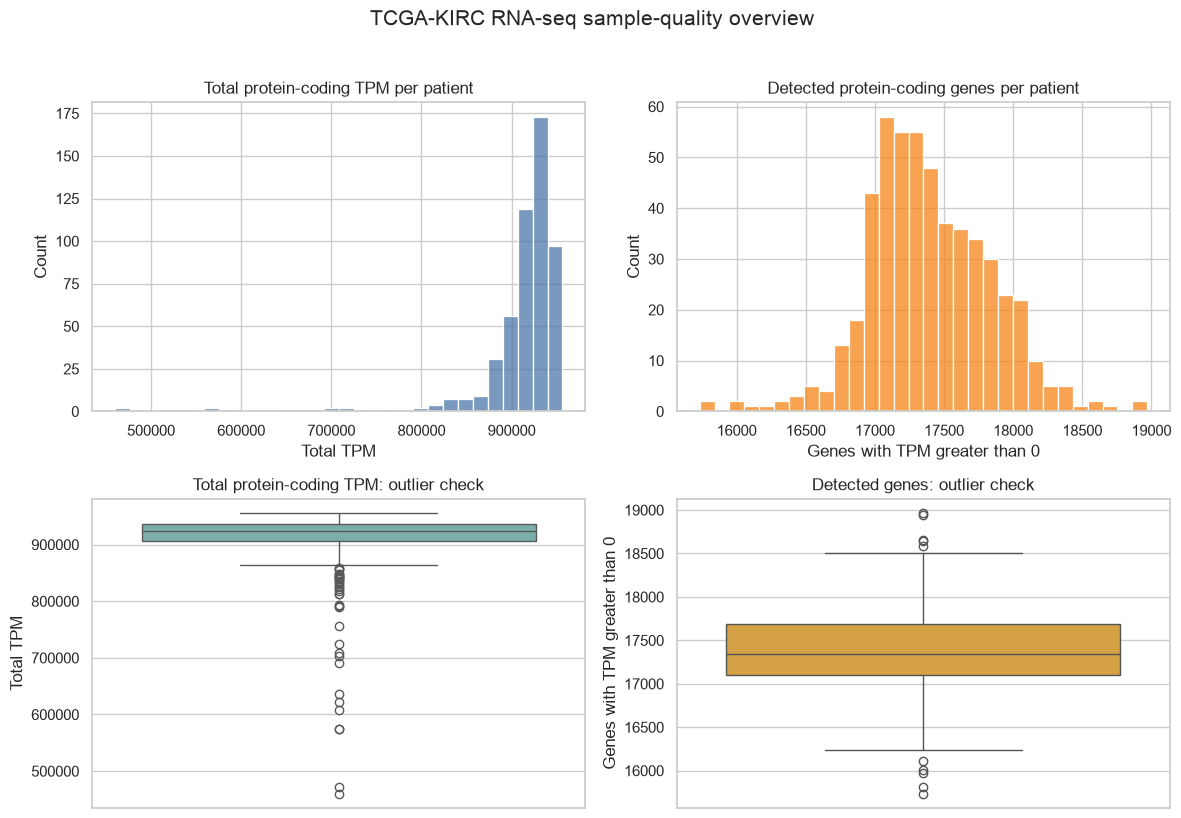

Figure saved as: figure_05_expression_sample_qc.png


In [17]:
# 03-18  Visualize sample-level TPM quality

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(
    data=sample_qc,
    x="total_protein_coding_TPM",
    bins=30,
    color="#4C78A8",
    ax=axes[0, 0],
)
axes[0, 0].set_title("Total protein-coding TPM per patient")
axes[0, 0].set_xlabel("Total TPM")

sns.boxplot(
    data=sample_qc,
    y="total_protein_coding_TPM",
    color="#72B7B2",
    ax=axes[1, 0],
)
axes[1, 0].set_title("Total protein-coding TPM: outlier check")
axes[1, 0].set_ylabel("Total TPM")

sns.histplot(
    data=sample_qc,
    x="detected_gene_count",
    bins=30,
    color="#F58518",
    ax=axes[0, 1],
)
axes[0, 1].set_title("Detected protein-coding genes per patient")
axes[0, 1].set_xlabel("Genes with TPM greater than 0")

sns.boxplot(
    data=sample_qc,
    y="detected_gene_count",
    color="#ECA82C",
    ax=axes[1, 1],
)
axes[1, 1].set_title("Detected genes: outlier check")
axes[1, 1].set_ylabel("Genes with TPM greater than 0")

fig.suptitle("TCGA-KIRC RNA-seq sample-quality overview", y=1.02, fontsize=15)
plt.tight_layout()

figure_file = RESULTS_DIR / "figures" / "figure_05_expression_sample_qc.png"
fig.savefig(figure_file, dpi=300, bbox_inches="tight")

plt.show()

print(f"Figure saved as: {figure_file.name}")

03-19 Apply log2(TPM + 1) transformation

In [18]:
# 03-19 Apply log2(TPM + 1) transformation

expression_log2_tpm = np.log2(expression_tpm + 1)

log2_tpm_file = (
    PROCESSED_DATA_DIR / "tcga_kirc_log2_tpm_protein_coding_by_patient.pkl.gz"
)

expression_log2_tpm.to_pickle(log2_tpm_file, compression="gzip")

print("Log2 TPM matrix shape:", expression_log2_tpm.shape)
print(f"Minimum log2(TPM + 1): {expression_log2_tpm.to_numpy().min():.2f}")
print(f"Maximum log2(TPM + 1): {expression_log2_tpm.to_numpy().max():.2f}")
print(f"Log2 TPM matrix saved as: {log2_tpm_file.name}")

Log2 TPM matrix shape: (19962, 518)
Minimum log2(TPM + 1): 0.00
Maximum log2(TPM + 1): 16.99
Log2 TPM matrix saved as: tcga_kirc_log2_tpm_protein_coding_by_patient.pkl.gz


This transformation reduces the huge influence of extremely highly expressed genes while preserving the patient-to-patient expression patterns that I need for survival analysis

## purpose 
03-20;Create the final matched clinical-expression cohort 

In [19]:
# 03-20 — Create the final matched clinical-expression cohort

clinical_file = (
    PROCESSED_DATA_DIR / "tcga_kirc_clinical_survival_analysis.csv"
)

clinical_data = pd.read_csv(clinical_file)

expression_patient_ids = set(expression_log2_tpm.columns)

matched_clinical_data = clinical_data[
    clinical_data["patient_id"].isin(expression_patient_ids)
].copy()

matched_clinical_data = matched_clinical_data.sort_values(
    "patient_id"
).reset_index(drop=True)

matched_patient_ids = matched_clinical_data["patient_id"].tolist()

expression_log2_tpm = expression_log2_tpm.loc[:, matched_patient_ids]

assert len(matched_clinical_data) == 518
assert expression_log2_tpm.shape[1] == 518
assert matched_clinical_data["patient_id"].tolist() == expression_log2_tpm.columns.tolist()

matched_clinical_file = (
    PROCESSED_DATA_DIR / "tcga_kirc_matched_clinical_survival_data.csv"
)

matched_clinical_data.to_csv(matched_clinical_file, index=False)

print("Matched clinical patients:", len(matched_clinical_data))
print("Matched expression patients:", expression_log2_tpm.shape[1])
print("Deaths in matched cohort:", matched_clinical_data["event_observed"].sum())
print(f"Matched clinical file saved as: {matched_clinical_file.name}")

Matched clinical patients: 518
Matched expression patients: 518
Deaths in matched cohort: 171
Matched clinical file saved as: tcga_kirc_matched_clinical_survival_data.csv


03-21  Standardize each gene across patients

In [20]:
# 03-21 — Standardize each gene across matched patients

gene_means = expression_log2_tpm.mean(axis=1)
gene_standard_deviations = expression_log2_tpm.std(axis=1)

zero_variance_genes = gene_standard_deviations[
    gene_standard_deviations == 0
].index

expression_log2_tpm = expression_log2_tpm.drop(index=zero_variance_genes)

gene_means = expression_log2_tpm.mean(axis=1)
gene_standard_deviations = expression_log2_tpm.std(axis=1)

expression_zscore = expression_log2_tpm.sub(gene_means, axis=0).div(
    gene_standard_deviations,
    axis=0,
)

assert expression_zscore.notna().all().all()
assert np.isfinite(expression_zscore.to_numpy()).all()

zscore_file = (
    PROCESSED_DATA_DIR
    / "tcga_kirc_log2_tpm_zscore_protein_coding_by_patient.pkl.gz"
)

expression_zscore.to_pickle(zscore_file, compression="gzip")

print("Genes before zero-variance removal:", len(expression_tpm))
print("Genes removed for zero variance:", len(zero_variance_genes))
print("Final standardized matrix shape:", expression_zscore.shape)
print(f"Standardized matrix saved as: {zscore_file.name}")

Genes before zero-variance removal: 19962
Genes removed for zero variance: 438
Final standardized matrix shape: (19524, 518)
Standardized matrix saved as: tcga_kirc_log2_tpm_zscore_protein_coding_by_patient.pkl.gz


A z-score of +1 means that patient’s gene expression is one standard deviation above the cohort average for that gene; -1 means one standard deviation below it

NOte : thats Those 438 genes had exactly the same 
expression value in every patient usually all zero 
so they contain no information for comparing survival
outcomes.Threfore I am removing them is the right decision.

03-22 Verify the standardized expression matrix

In [21]:
# 03-22 — Verify the standardized expression matrix

gene_zscore_means = expression_zscore.mean(axis=1)
gene_zscore_standard_deviations = expression_zscore.std(axis=1)

largest_mean_difference = gene_zscore_means.abs().max()
largest_standard_deviation_difference = (
    gene_zscore_standard_deviations.sub(1).abs().max()
)

print("Final genes:", expression_zscore.shape[0])
print("Final patients:", expression_zscore.shape[1])
print(f"Average gene z-score mean: {gene_zscore_means.mean():.6f}")
print(
    "Average gene z-score standard deviation: "
    f"{gene_zscore_standard_deviations.mean():.6f}"
)
print(f"Largest difference from mean 0: {largest_mean_difference:.6f}")
print(
    "Largest difference from standard deviation 1: "
    f"{largest_standard_deviation_difference:.6f}"
)

assert largest_mean_difference < 1e-4
assert largest_standard_deviation_difference < 1e-4

print("\n Standardization verification cmpleted .")

Final genes: 19524
Final patients: 518
Average gene z-score mean: 0.000000
Average gene z-score standard deviation: 1.000000
Largest difference from mean 0: 0.000016
Largest difference from standard deviation 1: 0.000000

 Standardization verification cmpleted .


03-23 Save annotation for the analysis genes

In [22]:
# 03-23 — Save annotation for the final analysis genes

gene_annotation_file = (
    PROCESSED_DATA_DIR / "tcga_kirc_protein_coding_gene_annotation.csv"
)

gene_annotation = pd.read_csv(gene_annotation_file)

final_gene_annotation = (
    gene_annotation
    .set_index("gene_id")
    .loc[expression_zscore.index]
    .reset_index()
)

assert len(final_gene_annotation) == expression_zscore.shape[0]
assert final_gene_annotation["gene_id"].is_unique

final_gene_annotation_file = (
    PROCESSED_DATA_DIR / "tcga_kirc_analysis_gene_annotation.csv"
)

final_gene_annotation.to_csv(final_gene_annotation_file, index=False)

print("Genes in final annotation:", len(final_gene_annotation))
print(f"Final annotation saved as: {final_gene_annotation_file.name}")

display(final_gene_annotation.head())

Genes in final annotation: 19524
Final annotation saved as: tcga_kirc_analysis_gene_annotation.csv


,gene_id,gene_name,gene_type
0,ENSG00000000003.15,TSPAN6,protein_coding
1,ENSG00000000005.6,TNMD,protein_coding
2,ENSG00000000419.13,DPM1,protein_coding
3,ENSG00000000457.14,SCYL3,protein_coding
4,ENSG00000000460.17,C1orf112,protein_coding


## summary

I have retrieved, quality-checked, and deduplicated GDC TCGA-KIRC primary-tumour STAR-count files,which gives me TPM expression data for 518 patients matched to the clinical survival cohort.

After log2(TPM + 1) transformation and removal of 438 genes with no variation, the final analysis matrix contains 19,524 standardized protein-coding genes across 518 patients (171 deaths).